# SCMIL OPM -- Interactive exploration of the 60 UNISIM-I-D scenarios (50 train + 10 test) -- V2

**Scope:** this notebook explores the raw dataset generated with OPM Flow for UNISIM-I-D -- `Sw`/`P`
fields in layer `k=2`, for each `(RATE_INJ1, LRAT_NA2)` combination. **It is not DeepONet-specific**:
it is general exploration of the simulation data, reusable by any neural-operator technique (DeepONet,
CPNO, future ones). That is why it lives here, under `OPM/OPERADOR NEURAL/`, next to the dataset,
rather than inside a technique-specific chapter folder.

**Date:** 10/04/2026 -- initial V1 (training 50 only). 10/06/2026 -- V2: relocated from
`SCMIL UNISIM1 DEEPONET/notebooks/` (where it lived by mistake, mixed in with the DeepONet chapter)
to this folder; incorporated the 10 independent test scenarios (`unisim1_deeponet_test10.h5`); fixed
the interactive viewer to mask inactive cells to `NaN` before plotting (same fix as `DeepONet_V1b`,
Master MD Sec. 9) instead of letting the colorbar auto-scale to physically meaningless values.

**Goal:** before training any neural operator, visualize the 60 generated scenarios (50
training/validation via LHS + 10 independent test: 5 interpolation + 5 stress) to visually confirm
that:
- the front advances reasonably in every case (no spurious NaN, no saturations outside the physical
  range),
- there is real diversity across scenarios (they are not near-identical),
- breakthrough at NA2 happens within the 5-year window in most cases,
- the 10 test scenarios land where they were designed to: the 5 interpolation ones inside the
  training range, the 5 stress ones at or beyond its edge (see Section 5).

**Explicit intent of each group (do not mix them up):**

| Group | How many | Purpose | How they were generated |
|---|---|---|---|
| `train_lhs` | 50 | Training + k-fold validation of the neural operators | Latin Hypercube Sampling, `SEED=42`, inside `RATE_INJ1∈[2000,6000]`, `LRAT_NA2∈[1500,4500]` |
| `test_interpolacion` | 5 (I1-I5) | Measure generalization **inside** the training range, at never-seen points | Manually chosen inside the same LHS range, not coinciding with any of the 50 |
| `test_estres` | 5 (E1-E5) | Measure generalization **near or beyond** the edge of the training range | Manually chosen, ~3% above the training maximum in `RATE_INJ1` and/or `LRAT_NA2` |

The 10 test scenarios are **never** used for training or for k-fold -- see the question in Section 5
and the note in the "Notes / next steps" section about when (and how) that could change.

**Note on the `Sw` range (verified during extraction):** `Sw` reaches `1.0` in some cells of layer
`k=2` **from `t=0`** (317 of 2296 active cells) -- this is not a simulation or extraction bug. The
deck has two different water-oil contacts per region (`EQUIL`, `3100 m` and `3174 m`); part of layer
`k=2` is geologically below that contact and starts 100% water-saturated. It is a real initial
condition of the field, not an artifact.

**Prerequisite:** this notebook assumes `unisim1_deeponet_dataset.h5` (50 scenarios) and
`unisim1_deeponet_test10.h5` (10 test scenarios) already exist, generated by their respective batch
pipelines (see `SCMIL_OPM_OPERADOR_NEURAL_MASTER_PLAN_EN.md`, Sections 4 and 5). If either is
missing, the loading cell will fail with a clear message.

**History:**

| Version | Date | Change |
|---|---|---|
| V1 | 10/04/2026 | Initial version (50 scenarios only) -- interactive viewer by scenario/time + summary grid. Lived in `SCMIL UNISIM1 DEEPONET/notebooks/`. |
| V2 | 10/06/2026 | Relocated to `OPM/OPERADOR NEURAL/` (general data exploration, not DeepONet-specific). Added the 10 independent test scenarios, with explicit group/intent in every plot. Fixed interactive viewer: masks inactive cells to `NaN` before plotting (fix from `DeepONet_V1b`, Master MD Sec. 9). New Section 5: parameter-space coverage, all 60 points colored by group. |

In [25]:
# === Scientific core ===
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib import rcParams

# === Data ===
import h5py
from pathlib import Path

# === Interactivity ===
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed
from IPython.display import display

import warnings
warnings.filterwarnings('ignore')

VERSION_ID = "V2"
TECNICA_ID = "OPM"  # general data exploration, not a specific neural-operator technique

print(f"{TECNICA_ID} {VERSION_ID} -- exploration notebook (60 scenarios: 50 train + 10 test)")

OPM V2 -- exploration notebook (60 scenarios: 50 train + 10 test)


## 1. Combined loading -- the 50 training scenarios + the 10 test scenarios

Expected format of each `.h5` (see master plan, Sections 4.3 and 5.3):

```text
unisim1_deeponet_dataset.h5          (50 training scenarios)
├─ static/            # K, porosity, actnum, etc. (layer k=2)
├─ scenarios/
│  ├─ params          (50, 2)              # [RATE_INJ1, LRAT_NA2]
│  ├─ time_days        (n_snapshots,)
│  ├─ pressure         (50, n_snapshots, nx, ny)
│  └─ swat             (50, n_snapshots, nx, ny)

unisim1_deeponet_test10.h5           (10 independent test scenarios)
├─ static/            # identical (same K, same k=2)
├─ scenarios/
│  ├─ params, escenario_id, tag, grupo, time_days, pressure, swat, wells/...
```

Both are loaded, concatenated in memory (50+10=60 scenarios, ~137 MB total -- fits in RAM without
issue) and a 60-string `grupo` array is built (`"train_lhs"` / `"test_interpolacion"` /
`"test_estres"`) that tags every scenario for the rest of the notebook. Adjust `DATASET_DIR` if the
`.h5` files are in another location (local, or mounted from Drive if running on Colab).

In [26]:
import os

IN_COLAB = Path("/content").exists()

if IN_COLAB:
    # Colab runs on a remote VM -- it cannot see your Windows disk (C:\...).
    # Both .h5 files must already be uploaded to your Google Drive.
    from google.colab import drive
    drive.mount("/content/drive")
    DATASET_DIR = Path("/content/drive/MyDrive/SCMIL_UNISIM1_OPERADOR_NEURAL/datasets")
else:
    # Local Jupyter/VS Code, on your Windows machine. V2: this notebook now lives in
    # OPM/OPERADOR NEURAL/, the same folder as the .h5 files -- simple relative path.
    DATASET_DIR = Path(
        r"C:\Users\guita\Desktop\PhD-ScimL-New\Analisis de PINNS\Claude\OPM\OPERADOR NEURAL"
    )

TRAIN_PATH = DATASET_DIR / "unisim1_deeponet_dataset.h5"
TEST_PATH = DATASET_DIR / "unisim1_deeponet_test10.h5"

for p in (TRAIN_PATH, TEST_PATH):
    if not p.exists():
        extra = (
            "\nYou are on Colab: upload both .h5 files to your Drive, under "
            "'SCMIL_UNISIM1_OPERADOR_NEURAL/datasets/'." if IN_COLAB else
            "\nAdjust DATASET_DIR if the files are in another local location."
        )
        raise FileNotFoundError(
            f"Could not find {p}.\n"
            "This notebook assumes both batch pipelines (50 + 10 test) have already run "
            "(see SCMIL_OPM_OPERADOR_NEURAL_MASTER_PLAN_EN.md, Sections 4-5)." + extra
        )

with h5py.File(TRAIN_PATH, "r") as f_train:
    actnum = f_train["static/actnum"][:].astype(bool)
    params_train = f_train["scenarios/params"][:]            # (50, 2)
    time_days = f_train["scenarios/time_days"][:]             # (n_snapshots,)
    swat_train = f_train["scenarios/swat"][:]                 # (50, n_snapshots, nx, ny)
    pressure_train = f_train["scenarios/pressure"][:]

with h5py.File(TEST_PATH, "r") as f_test:
    params_test = f_test["scenarios/params"][:]               # (10, 2)
    swat_test = f_test["scenarios/swat"][:]
    pressure_test = f_test["scenarios/pressure"][:]
    tag_test = [t.decode() if isinstance(t, bytes) else t for t in f_test["scenarios/tag"][:]]
    grupo_test_raw = [g.decode() if isinstance(g, bytes) else g for g in f_test["scenarios/grupo"][:]]

params = np.concatenate([params_train, params_test], axis=0)              # (60, 2)
swat = np.concatenate([swat_train, swat_test], axis=0)                    # (60, n_snapshots, nx, ny)
pressure = np.concatenate([pressure_train, pressure_test], axis=0)

n_escenarios, n_snapshots, nx, ny = swat.shape
time_years = time_days / 365.25

# Explicit group per scenario -- used in every title/color from here on.
# The first 50 are ALWAYS train_lhs (fixed concatenation order); the last 10 inherit
# their real group (interpolation/stress) from the test file itself, not guessed by index.
grupo = np.array(["train_lhs"] * 50 + [
    "test_interpolacion" if "interp" in g else "test_estres" for g in grupo_test_raw
])
tag = np.array([f"#{i}" for i in range(50)] + tag_test)

GRUPO_COLOR = {"train_lhs": "#1f77b4", "test_interpolacion": "#2ca02c", "test_estres": "#d62728"}

print(f"Environment: {'Colab' if IN_COLAB else 'local'}")
print(f"Total scenarios: {n_escenarios} (train_lhs={np.sum(grupo=='train_lhs')}, "
      f"test_interpolacion={np.sum(grupo=='test_interpolacion')}, "
      f"test_estres={np.sum(grupo=='test_estres')})")
print(f"Snapshots per scenario: {n_snapshots} (0 to {time_years[-1]:.2f} years)")
print(f"Grid (layer k=2): {nx} x {ny} | active cells: {actnum.sum()} ({100*actnum.mean():.1f}%)")
print()
print("Parameter range, all 60 scenarios:")
print(f"  RATE_INJ1: [{params[:,0].min():.0f}, {params[:,0].max():.0f}] sm3/d")
print(f"  LRAT_NA2:  [{params[:,1].min():.0f}, {params[:,1].max():.0f}] sm3/d")

Environment: local
Total scenarios: 60 (train_lhs=50, test_interpolacion=5, test_estres=5)
Snapshots per scenario: 61 (0 to 5.00 years)
Grid (layer k=2): 81 x 58 | active cells: 2296 (48.9%)

Parameter range, all 60 scenarios:
  RATE_INJ1: [2062, 6200] sm3/d
  LRAT_NA2:  [1549, 4650] sm3/d


## 2. Interactive viewer -- one scenario (of 60), one time step at a time

Sliders: `escenario` (0-59, includes the 50 training scenarios and the 10 test ones at the end),
`snapshot` (0 to n_snapshots-1), and a field selector (`Sw` or `P`). The title shows
`(RATE_INJ1, LRAT_NA2)` **and the group** of the active scenario, so it is never ambiguous whether you
are looking at a training or a test case. Inactive cells (`ACTNUM=0`, 51.1% of the grid) are masked
to `NaN` before plotting -- same fix as `DeepONet_V1b` (Master MD Sec. 9) -- so the colorbar does not
auto-scale to physically meaningless values.

**V2.1:** rewritten in **Plotly** (`go.Heatmap`, same engine as the Section 6/7 animations) instead of
`matplotlib` -- the previous viewer redrew a full PNG image from scratch on every slider move, which
felt slow.

**V2.2 (reverted from `FigureWidget` to `go.Figure` + `fig.show()`):** `go.FigureWidget` was tried to
update the heatmap in place (faster in theory), but with `plotly==7.1.0` + `anywidget==0.11.0` (the
versions installed in this project) `batch_update()` raises `KeyError: 'uid'` while syncing the widget
with the frontend -- a known bug in the `anywidget`-based `FigureWidget` backend for this version
combination, not an error in this notebook or the data. Reverted to the stable version: a fresh
`go.Figure` + `fig.show()` on every `interact` call -- still Plotly (much faster than `matplotlib`,
which redrew a fully rasterized image), just without `FigureWidget`'s in-place optimization. If
`plotly`/`anywidget` get updated and the bug is fixed, this can switch back to `FigureWidget`.

In [27]:
import plotly.graph_objects as go

INJ1_IJ = (9, 39)
NA2_IJ = (20, 35)


def compute_map(escenario_idx, snapshot_idx, campo):
    field = swat if campo == "Sw" else pressure
    data = field[escenario_idx, snapshot_idx, :, :]
    return np.where(actnum, data, np.nan)  # mask inactive cells before plotting


def titulo_viewer(escenario_idx, snapshot_idx, campo):
    rate_inj1, lrat_na2 = params[escenario_idx]
    t_years = time_years[snapshot_idx]
    g = grupo[escenario_idx]
    return (f"{TECNICA_ID} {VERSION_ID} -- scenario {escenario_idx} [{g}] "
            f"(RATE_INJ1={rate_inj1:.0f}, LRAT_NA2={lrat_na2:.0f}) -- "
            f"t={t_years:.2f} years -- field={campo}")


def plot_escenario(escenario_idx, snapshot_idx, campo):
    data = compute_map(escenario_idx, snapshot_idx, campo)
    colorscale = "Blues" if campo == "Sw" else "Viridis"

    fig = go.Figure(data=[
        go.Heatmap(z=data.T, colorscale=colorscale,
                   zmin=float(np.nanmin(data)), zmax=float(np.nanmax(data)),
                   colorbar=dict(title=campo)),
        go.Scatter(x=[INJ1_IJ[0]], y=[INJ1_IJ[1]], mode="markers+text",
                   marker=dict(symbol="triangle-up", color="red", size=14),
                   text=["INJ1"], textposition="top center", name="INJ1 (injector)"),
        go.Scatter(x=[NA2_IJ[0]], y=[NA2_IJ[1]], mode="markers+text",
                   marker=dict(color="black", size=12),
                   text=["NA2"], textposition="top center", name="NA2 (producer)"),
    ])
    fig.update_layout(
        title=titulo_viewer(escenario_idx, snapshot_idx, campo),
        xaxis_title="i (cell, x direction)",
        yaxis_title="j (cell, y direction)",
        width=760, height=600,
    )
    fig.show()


interact(
    plot_escenario,
    escenario_idx=widgets.IntSlider(min=0, max=n_escenarios - 1, step=1, value=0, description="scenario"),
    snapshot_idx=widgets.IntSlider(min=0, max=n_snapshots - 1, step=1, value=n_snapshots // 2, description="snapshot"),
    campo=widgets.ToggleButtons(options=["Sw", "P"], description="field"),
);

interactive(children=(IntSlider(value=0, description='scenario', max=59), IntSlider(value=30, description='sna…

## 3. Summary view -- all 60 scenarios at once (final snapshot)

Thumbnail grid (`Sw` at the end of the simulated horizon, ~5 years) to compare diversity across
scenarios at a glance. The first 50 are training (`#0`-`#49`); the last 10 are test, labeled with
their real `tag` (`I1`-`I5`, `E1`-`E5`) instead of a generic index, so it is obvious which ones are
test cases just by looking at the grid.

In [28]:
def grid_resumen(snapshot_idx=n_snapshots - 1, campo="Sw"):
    field = swat if campo == "Sw" else pressure
    ncols, nrows = 10, int(np.ceil(n_escenarios / 10))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.6, nrows * 1.6))
    data_snap = np.where(actnum[None], field[:, snapshot_idx, :, :], np.nan)
    vmin, vmax = np.nanmin(data_snap), np.nanmax(data_snap)

    for idx in range(nrows * ncols):
        ax = axes.flat[idx]
        ax.axis("off")
        if idx >= n_escenarios:
            continue
        ax.imshow(data_snap[idx].T, origin="lower", cmap="Blues" if campo == "Sw" else "viridis",
                  vmin=vmin, vmax=vmax, aspect="auto")
        color = GRUPO_COLOR[grupo[idx]]
        ax.set_title(tag[idx], fontsize=7, color=color, fontweight="bold" if idx >= 50 else "normal")

    fig.suptitle(
        f"{TECNICA_ID} {VERSION_ID} -- {campo} across {n_escenarios} scenarios "
        f"(blue=train_lhs, green=test_interpolacion, red=test_estres) -- "
        f"t={time_years[snapshot_idx]:.2f} years",
        fontsize=12, fontweight="bold",
    )
    plt.tight_layout()
    plt.show()


interact(
    grid_resumen,
    snapshot_idx=widgets.IntSlider(min=0, max=n_snapshots - 1, step=1, value=n_snapshots - 1, description="snapshot"),
    campo=widgets.ToggleButtons(options=["Sw", "P"], description="field"),
);

interactive(children=(IntSlider(value=60, description='snapshot', max=60), ToggleButtons(description='field', …

## 4. Quick diagnostic -- physical range and breakthrough per scenario (and per group)

Cheap check before training/evaluating: `Sw` must stay within `[Swc, 1-Sor]` (no spurious NaN, no
negatives), and breakthrough at NA2 (baseline reference ~1.7 years) should happen within the 5
simulated years in most scenarios. The global summary (60) is reported, plus a separate one per
group -- to confirm the stress scenarios (edges of the range) do not behave pathologically.

In [29]:
sw_na2_series = swat[:, :, NA2_IJ[0], NA2_IJ[1]]  # (n_escenarios, n_snapshots)
sw_na2_inicial = sw_na2_series[:, 0]

# breakthrough: first snapshot where Sw(NA2) rises > 0.02 above its initial value
umbral = 0.02
breakthrough_idx = np.full(n_escenarios, -1)
for e in range(n_escenarios):
    sube = np.where(sw_na2_series[e] - sw_na2_inicial[e] > umbral)[0]
    if len(sube) > 0:
        breakthrough_idx[e] = sube[0]

sin_breakthrough = np.where(breakthrough_idx == -1)[0]
print(f"Scenarios WITHOUT breakthrough within the simulated window: {len(sin_breakthrough)} of {n_escenarios}")
if len(sin_breakthrough) > 0:
    print("  Indices:", sin_breakthrough.tolist())
    for e in sin_breakthrough:
        print(f"    {tag[e]} [{grupo[e]}]: RATE_INJ1={params[e,0]:.0f}, LRAT_NA2={params[e,1]:.0f}")

t_breakthrough_anos = np.where(breakthrough_idx >= 0, time_years[np.clip(breakthrough_idx, 0, None)], np.nan)
print()
print(f"Global breakthrough (60) -- min={np.nanmin(t_breakthrough_anos):.2f} years, "
      f"median={np.nanmedian(t_breakthrough_anos):.2f} years, "
      f"max={np.nanmax(t_breakthrough_anos):.2f} years "
      f"(measured baseline reference: ~1.7 years)")

print()
print("Breakthrough per group:")
for g in ("train_lhs", "test_interpolacion", "test_estres"):
    mask_g = grupo == g
    vals = t_breakthrough_anos[mask_g]
    print(f"  {g:20s} (n={mask_g.sum():2d}): min={np.nanmin(vals):.2f}  median={np.nanmedian(vals):.2f}  max={np.nanmax(vals):.2f} years")

# IMPORTANT: layer k=2 has INACTIVE cells (ACTNUM=0), deliberately stored as NaN
# (same project convention). That is why we use nanmin/nanmax.
sw_min, sw_max = float(np.nanmin(swat)), float(np.nanmax(swat))
n_nan = int(np.isnan(swat[:]).sum())
n_total = swat.size
print(f"\nGlobal Sw range in ACTIVE cells, all {n_escenarios} scenarios: [{sw_min:.4f}, {sw_max:.4f}] "
      f"({'OK, within [0,1]' if 0 <= sw_min and sw_max <= 1 else 'WARNING: outside physical range'})")
print(f"NaN cells (inactive in layer k=2, same pattern across all 60 scenarios): {n_nan}/{n_total} ({100*n_nan/n_total:.1f}%)")

Scenarios WITHOUT breakthrough within the simulated window: 0 of 60

Global breakthrough (60) -- min=1.66 years, median=1.83 years, max=2.58 years (measured baseline reference: ~1.7 years)

Breakthrough per group:
  train_lhs            (n=50): min=1.66  median=1.83  max=2.58 years
  test_interpolacion   (n= 5): min=1.66  median=1.83  max=2.50 years
  test_estres          (n= 5): min=1.66  median=1.75  max=2.33 years

Global Sw range in ACTIVE cells, all 60 scenarios: [0.1656, 1.0000] (OK, within [0,1])
NaN cells (inactive in layer k=2, same pattern across all 60 scenarios): 8791320/17194680 (51.1%)


## 5. Parameter-space coverage -- all 60 points, colored by group

Answers at a glance "where do the 10 test scenarios fall relative to the 50 training ones?": the 5
interpolation points (green) should fall **inside** the training rectangle (blue); the 5 stress
points (red) should fall at or outside its edge. This is also the visual reference for the question
in the "Notes / next steps" section: if the k-fold error turns out high in one zone of the rectangle,
this plot shows whether the LHS actually covers that zone.

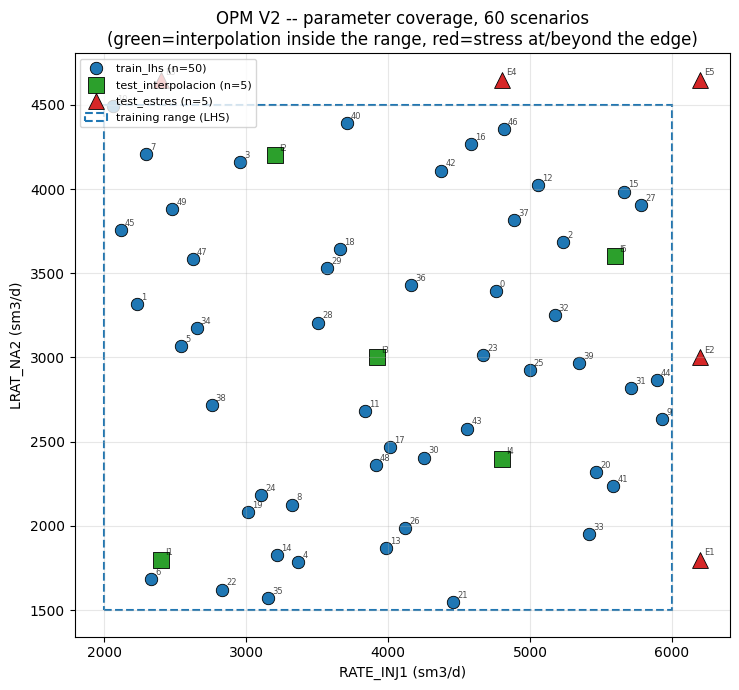

In [30]:
fig, ax = plt.subplots(figsize=(7.5, 7))
for g in ("train_lhs", "test_interpolacion", "test_estres"):
    mask_g = grupo == g
    ax.scatter(params[mask_g, 0], params[mask_g, 1], c=GRUPO_COLOR[g], s=80 if g == "train_lhs" else 130,
               edgecolors="k", linewidths=0.6, label=f"{g} (n={mask_g.sum()})",
               marker="o" if g == "train_lhs" else ("s" if g == "test_interpolacion" else "^"))
for e in range(n_escenarios):
    ax.annotate(tag[e].lstrip("#"), (params[e, 0], params[e, 1]), fontsize=6, alpha=0.7,
                xytext=(3, 3), textcoords="offset points")

RATE_INJ1_RANGE = (2000.0, 6000.0)
LRAT_NA2_RANGE = (1500.0, 4500.0)
rect = plt.Rectangle((RATE_INJ1_RANGE[0], LRAT_NA2_RANGE[0]),
                      RATE_INJ1_RANGE[1] - RATE_INJ1_RANGE[0], LRAT_NA2_RANGE[1] - LRAT_NA2_RANGE[0],
                      fill=False, edgecolor="#1f77b4", linestyle="--", linewidth=1.5,
                      label="training range (LHS)")
ax.add_patch(rect)

ax.set_xlabel("RATE_INJ1 (sm3/d)")
ax.set_ylabel("LRAT_NA2 (sm3/d)")
ax.set_title(f"{TECNICA_ID} {VERSION_ID} -- parameter coverage, 60 scenarios\n"
             f"(green=interpolation inside the range, red=stress at/beyond the edge)")
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Plotly animation -- step through the 60 scenarios with Play

Unlike the Section 2 viewer (manual slider), this automatically animates the 60 scenarios one after
another at the same time step (`SNAPSHOT_ANIM`, the last one by default) -- hit **Play** and watch
them go by, or drag the bottom slider to jump to a specific scenario. Each frame's title shows
`(RATE_INJ1, LRAT_NA2)` **and the group** of the active scenario.

In [31]:
import plotly.graph_objects as go

SNAPSHOT_ANIM = n_snapshots - 1  # change here to animate at another time step (0 = t=0)
CAMPO_ANIM = "Sw"                # "Sw" or "P"

field_anim = swat if CAMPO_ANIM == "Sw" else pressure
data_anim = np.where(actnum[None], field_anim[:, SNAPSHOT_ANIM, :, :], np.nan)  # (60, nx, ny)
vmin, vmax = float(np.nanmin(data_anim)), float(np.nanmax(data_anim))
colorscale = "Blues" if CAMPO_ANIM == "Sw" else "Viridis"
t_anim_years = time_years[SNAPSHOT_ANIM]


def titulo(e):
    return (f"{TECNICA_ID} {VERSION_ID} -- scenario {tag[e]} [{grupo[e]}] "
            f"(RATE_INJ1={params[e,0]:.0f}, LRAT_NA2={params[e,1]:.0f}) -- "
            f"t={t_anim_years:.2f} years -- field={CAMPO_ANIM}")


frames = [
    go.Frame(
        data=[go.Heatmap(z=data_anim[e].T, colorscale=colorscale, zmin=vmin, zmax=vmax,
                          colorbar=dict(title=CAMPO_ANIM))],
        name=str(e),
        traces=[0],
        layout=go.Layout(title_text=titulo(e)),
    )
    for e in range(n_escenarios)
]

fig = go.Figure(
    data=[go.Heatmap(z=data_anim[0].T, colorscale=colorscale, zmin=vmin, zmax=vmax,
                      colorbar=dict(title=CAMPO_ANIM))],
    frames=frames,
)
fig.add_trace(go.Scatter(x=[INJ1_IJ[0]], y=[INJ1_IJ[1]], mode="markers+text",
                          marker=dict(symbol="triangle-up", color="red", size=14),
                          text=["INJ1"], textposition="top center", name="INJ1 (injector)"))
fig.add_trace(go.Scatter(x=[NA2_IJ[0]], y=[NA2_IJ[1]], mode="markers+text",
                          marker=dict(color="black", size=12),
                          text=["NA2"], textposition="top center", name="NA2 (producer)"))

fig.update_layout(
    title=titulo(0),
    xaxis_title="i (cell, x direction)",
    yaxis_title="j (cell, y direction)",
    width=760, height=620,
    updatemenus=[dict(
        type="buttons", showactive=False, x=0.05, y=1.12, xanchor="left",
        buttons=[
            dict(label="Play", method="animate",
                 args=[None, {"frame": {"duration": 500, "redraw": True}, "fromcurrent": True,
                               "transition": {"duration": 0}}]),
            dict(label="Pause", method="animate",
                 args=[[None], {"frame": {"duration": 0, "redraw": False}, "mode": "immediate"}]),
        ],
    )],
    sliders=[dict(
        active=0, x=0.05, y=-0.02, len=0.9,
        currentvalue={"prefix": "scenario: "},
        steps=[dict(method="animate", label=tag[e],
                     args=[[str(e)], {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"}])
               for e in range(n_escenarios)],
    )],
)
fig.show()

## 7. Plotly animation -- `Sw` and `P` together, side by side, same Play (60 scenarios)

Directly answers "saturation and pressure acting at the same time?": two synchronized panels (`Sw`
left, `P` right) that advance together with the same Play button/slider -- same scenario, same time
step, both fields at once, all 60 scenarios included.

In [32]:
from plotly.subplots import make_subplots

SNAPSHOT_ANIM2 = n_snapshots - 1  # change here to animate at another time step

sw_anim = np.where(actnum[None], swat[:, SNAPSHOT_ANIM2, :, :], np.nan)
p_anim = np.where(actnum[None], pressure[:, SNAPSHOT_ANIM2, :, :], np.nan)
sw_vmin, sw_vmax = float(np.nanmin(sw_anim)), float(np.nanmax(sw_anim))
p_vmin, p_vmax = float(np.nanmin(p_anim)), float(np.nanmax(p_anim))
t2_years = time_years[SNAPSHOT_ANIM2]


def titulo2(e):
    return (f"{TECNICA_ID} {VERSION_ID} -- scenario {tag[e]} [{grupo[e]}] "
            f"(RATE_INJ1={params[e,0]:.0f}, LRAT_NA2={params[e,1]:.0f}) -- "
            f"t={t2_years:.2f} years -- Sw (left) and P (right)")


fig2 = make_subplots(rows=1, cols=2, subplot_titles=["Sw", "P"], horizontal_spacing=0.12)
fig2.add_trace(go.Heatmap(z=sw_anim[0].T, colorscale="Blues", zmin=sw_vmin, zmax=sw_vmax,
                           colorbar=dict(title="Sw", x=0.43)), row=1, col=1)
fig2.add_trace(go.Heatmap(z=p_anim[0].T, colorscale="Viridis", zmin=p_vmin, zmax=p_vmax,
                           colorbar=dict(title="P [bar]", x=1.0)), row=1, col=2)
for col in (1, 2):
    fig2.add_trace(go.Scatter(x=[INJ1_IJ[0]], y=[INJ1_IJ[1]], mode="markers",
                               marker=dict(symbol="triangle-up", color="red", size=12),
                               showlegend=(col == 1), name="INJ1"), row=1, col=col)
    fig2.add_trace(go.Scatter(x=[NA2_IJ[0]], y=[NA2_IJ[1]], mode="markers",
                               marker=dict(color="black", size=10),
                               showlegend=(col == 1), name="NA2"), row=1, col=col)

frames2 = [go.Frame(
    data=[go.Heatmap(z=sw_anim[e].T, colorscale="Blues", zmin=sw_vmin, zmax=sw_vmax),
          go.Heatmap(z=p_anim[e].T, colorscale="Viridis", zmin=p_vmin, zmax=p_vmax)],
    traces=[0, 1], name=str(e), layout=go.Layout(title_text=titulo2(e)),
) for e in range(n_escenarios)]
fig2.frames = frames2

fig2.update_layout(
    title=titulo2(0), width=1200, height=620,
    updatemenus=[dict(
        type="buttons", showactive=False, x=0.0, y=1.15, xanchor="left",
        buttons=[
            dict(label="Play", method="animate",
                 args=[None, {"frame": {"duration": 500, "redraw": True}, "fromcurrent": True,
                               "transition": {"duration": 0}}]),
            dict(label="Pause", method="animate",
                 args=[[None], {"frame": {"duration": 0, "redraw": False}, "mode": "immediate"}]),
        ],
    )],
    sliders=[dict(
        active=0, x=0.05, y=-0.05, len=0.9, currentvalue={"prefix": "scenario: "},
        steps=[dict(method="animate", label=tag[e],
                     args=[[str(e)], {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"}])
               for e in range(n_escenarios)],
    )],
)
fig2.show()

## Notes / next steps

- This notebook is exploratory: it confirms the quality of the raw data before training/evaluating,
  it does not train anything.
- If several scenarios end up in `sin_breakthrough` (Section 4), check whether the 5-year horizon is
  insufficient for the low end of the rate range -- option: extend the horizon only for those specific
  scenarios, not for all 60.
- **Can the 5 interpolation scenarios (I1-I5) be used for training?** Yes -- they are already real OPM
  simulations with the same `K`/grid/PVT/horizon as the 50, so folding them in is pure array
  concatenation (`params`/`pressure`/`swat`, exactly as Section 1 of this notebook already does)
  **with no need to re-simulate anything**. The reason NOT to do it today: I1-I5 (and E1-E5) are
  precisely the set reserved to measure honest generalization -- if moved into training, they stop
  serving that purpose and the DeepONet/CPNO notebooks' k-fold loses its independent check.
- **How to extend the training set beyond 50 without touching the test set?** Generate **new**
  scenarios (new `RATE_INJ1`/`LRAT_NA2` points, not the 10 already reserved) with the same pipeline
  used for the original 50 (`scripts/run_batch_50.sh` + `scripts/extraer_50_escenarios.py`, adapting
  the LHS range/seed) and concatenate their extraction into the training `.h5` -- the same
  concatenation pattern this Section 1 already uses to combine train+test. This does require running
  OPM again (~1.65 min per new scenario, see master plan Section 4.3), unlike I1-I5 which already
  exist.
- Next step after validating here: training notebooks (`DeepONet_V1a/V1b`, `CPNO_V1a`, in their
  respective chapter folders) and evaluation against test10 (`DeepONet_V1b_Evaluacion_Test10`).